In [1]:
# %load_ext autoreload
# %autoreload 2
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent.parent.parent.parent.parent
sys.path.insert(0, str(PROJECT_ROOT))
print(PROJECT_ROOT)

from src.inference import generate, encode_cells, get_latent_mean, get_mean, load_data, load_model, sample_around_point, calc_r2_pearson
import scanpy as sc
import os
import anndata
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.pyplot import rc_context
import anndata
import seaborn as sns
import torch
import torch
import torch.distributed as dist
from torch.nn.parallel import DistributedDataParallel as DDP
import scipy.sparse as sp
print("CUDA Available: ", torch.cuda.is_available())
print("Number of GPUs: ", torch.cuda.device_count())
from matplotlib import font_manager
font_manager.fontManager.addfont("../../../arial.ttf")
plt.rcParams["font.family"] = "Arial"
plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 15,
    "pdf.fonttype": 42,
})
plt.rcParams["hatch.linewidth"] = 1


/lustre/work/yaolab/mzhou10/squidiff_practice/Squidiff/project_v3
CUDA Available:  True
Number of GPUs:  1


In [2]:
def check_nan(adata, name):
    X = adata.X

    if sp.issparse(X):
        nan_count = np.isnan(X.data).sum()
    else:
        nan_count = np.isnan(X).sum()

    print(f"{name} NaN count:", nan_count)

In [3]:

real_data_origin = sc.read_h5ad(f"../../input/test_data_day_19.h5ad")
real_data = real_data_origin[real_data_origin.obs['Group']==19]
# real_data = sc.read_h5ad("../../input/plant_test_day0_data.h5ad")
print("real_data:",real_data)

# select top 200 highly variable genes
sc.pp.highly_variable_genes(real_data, n_top_genes=200)

hvg_idx = np.where(real_data.var["highly_variable"])[0]

print(hvg_idx)
print(len(hvg_idx))



real_data: View of AnnData object with n_obs × n_vars = 5592 × 55450
    obs: 'CellID_Library', 'new_cellid_unique', 'doublet_score', 'embryonic_period', 'day', 'gender', 'mouse_part_summary', 'library_time', 'sample', 'n_counts', 'n_genes', 'percent_mito', 'predict_doublet', 'Gja5+_label', 'organ', 'label', 'Group'
    var: 'Ensembl_id'
    uns: 'Gja5+_label_colors', 'clusters_colors', 'clustes_colors', 'day_colors', 'embryonic_period_colors', 'hvg', 'label_2024_colors', 'label_colors', 'label_endoMT_colors', 'label_endo_colors', 'leiden', 'leiden_colors', 'mouse_part_summary_colors', 'neighbors', 'organ_colors', 'predict_label_colors', 'predict_proba', 'subtype_colors'
    obsm: 'X_pca', 'X_tsne', 'X_umap'
    obsp: 'connectivities', 'distances'


/home/yaolab/mzhou10/.conda/envs/celldiffgen/lib/python3.8/site-packages/scanpy/preprocessing/_highly_variable_genes.py:553: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns["hvg"] = {"flavor": flavor}


[  656   689  1022  1098  1172  1173  1579  1588  2194  2203  2254  2362
  2437  2735  2737  2850  2882  2960  3320  3328  3493  3745  3966  3992
  4078  4220  4538  4690  4899  5026  5746  5792  6166  6536  6540  6640
  6671  6694  6796  6837  6838  6850  7389  7453  7573  7949  8168  8868
  8965  9247 10649 10678 11188 12109 12809 12841 13265 13301 13315 13501
 13548 13739 13822 14079 14398 14495 14528 14569 14577 14616 14618 14697
 14856 15396 16202 16291 16501 16674 16675 16716 16877 16887 17086 17333
 17911 18017 18466 18608 18637 19161 19224 20175 20566 20640 21437 22467
 22867 22874 23557 23696 24006 24009 24121 24129 24759 25095 25343 25881
 26220 26390 26555 26638 27415 27625 27649 27663 27911 28869 29454 29853
 29936 30396 30423 30740 30866 30871 30958 31185 31199 31402 31403 31485
 31704 31803 32012 32588 32589 32591 32961 33202 33300 33777 33854 34038
 34145 34327 34342 34424 34428 34431 34589 34666 34928 35594 36249 36936
 37056 37862 38026 38574 38705 39580 39625 39993 40

In [4]:
r2_list = []
pearsonr_list = []

predict_data: AnnData object with n_obs × n_vars = 5592 × 55450
real_data: (5592, 200)
predict_data: (5592, 200)
R2: 0.7534423269934198
Pearson: 0.8874191933413766
5.569802292682582 4.8702583


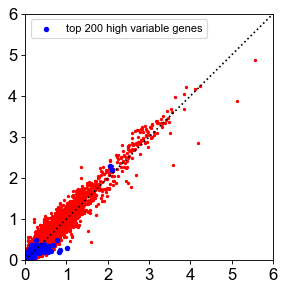

In [5]:
predict_data = sc.read_h5ad(f"../experiments/mice_exp6_infer_day_except_19_by_7_18_1_percent/interception_predict_to_day_19.h5ad")
print("predict_data:",predict_data)
predict_data.X = predict_data.X.astype(np.float64)
r2, pearsonr,real,predict = calc_r2_pearson(real_data,predict_data)

# keep only the same 200 HVGs
real_data_c = real_data[:, hvg_idx].copy()
predict_data_c = predict_data[:, hvg_idx].copy()

print("real_data:", real_data_c.shape)
print("predict_data:", predict_data_c.shape)

predict_data_c.X = predict_data_c.X.astype(np.float64)

r2, pearsonr, real_high, predict_high = calc_r2_pearson(  
    real_data_c,
    predict_data_c
)

print("R2:", r2)
print("Pearson:", pearsonr)

r2_list.append(r2)
pearsonr_list.append(pearsonr)

fig, ax = plt.subplots(1,1,figsize=(4,4),dpi=80)
plt.scatter(
    predict,
    real,
    s=4,
    c="red"
)
plt.scatter(
    predict_high,
    real_high,
    s=15,
    c="blue",
    label="top 200 high variable genes"
)
limit = np.ceil(max(np.max(predict), np.max(real)))
print(np.max(predict),np.max(real))
plt.plot([0, limit], [0, limit], color="black", linestyle=":")
plt.xlim([0, limit])
plt.ylim([0, limit])
ticks = np.arange(0, limit+1, 1)
ax.set_xticks(ticks)
ax.set_yticks(ticks)
# if limit <= 8:
#   ticks = np.arange(0, limit + 1, 1)
# else:    
#   ticks = np.arange(0, limit + 1, 100)
ax.legend(loc="upper left", fontsize=10, frameon=True)
fig.savefig(os.path.join(f"day7_day10_predict_day19_big_training_set_1_percent_high_variable_genes.pdf"), bbox_inches="tight")

predict_data: AnnData object with n_obs × n_vars = 5592 × 55450
real_data: (5592, 200)
predict_data: (5592, 200)
R2: 0.7214619461256548
Pearson: 0.869530345541863
4.775421039549066 4.8702583


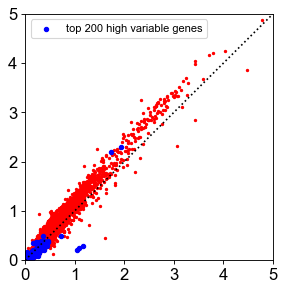

In [6]:
predict_data = sc.read_h5ad(f"../experiments/mice_exp6_infer_day_except_19_by_7_18_10_percent/interception_predict_to_day_19.h5ad")
print("predict_data:",predict_data)
predict_data.X = predict_data.X.astype(np.float64)
r2, pearsonr,real,predict = calc_r2_pearson(real_data,predict_data)
# keep only the same 200 HVGs
real_data_c = real_data[:, hvg_idx].copy()
predict_data_c = predict_data[:, hvg_idx].copy()

print("real_data:", real_data_c.shape)
print("predict_data:", predict_data_c.shape)

predict_data_c.X = predict_data_c.X.astype(np.float64)

r2, pearsonr, real_high, predict_high = calc_r2_pearson(  
    real_data_c,
    predict_data_c
)

print("R2:", r2)
print("Pearson:", pearsonr)
r2_list.append(r2)
pearsonr_list.append(pearsonr)
fig, ax = plt.subplots(1,1,figsize=(4,4),dpi=80)
plt.scatter(
    predict,
    real,
    s=4,
    c="red"
)
plt.scatter(
    predict_high,
    real_high,
    s=15,
    c="blue",
    label="top 200 high variable genes"
)
limit = np.ceil(max(np.max(predict), np.max(real)))
print(np.max(predict),np.max(real))
plt.plot([0, limit], [0, limit], color="black", linestyle=":")
plt.xlim([0, limit])
plt.ylim([0, limit])
ticks = np.arange(0, limit+1, 1)
ax.set_xticks(ticks)
ax.set_yticks(ticks)
# if limit <= 8:
#   ticks = np.arange(0, limit + 1, 1)
# else:    
#   ticks = np.arange(0, limit + 1, 100)
ax.legend(loc="upper left", fontsize=10, frameon=True)

fig.savefig(os.path.join(f"day7_day10_predict_day19_big_training_set_10_percent_high_variable_genes.pdf"), bbox_inches="tight")

predict_data: AnnData object with n_obs × n_vars = 5592 × 55450
real_data: (5592, 200)
predict_data: (5592, 200)
R2: 0.8926699099962042
Pearson: 0.9461420980526285
5.1374500016968305 4.8702583


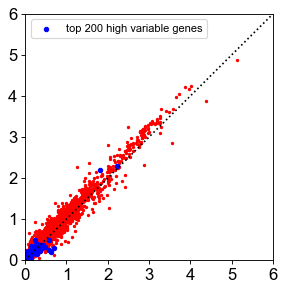

In [7]:
predict_data = sc.read_h5ad(f"../experiments/mice_exp6_infer_day_except_19_by_7_18_25_percent/interception_predict_to_day_19.h5ad")
print("predict_data:",predict_data)
predict_data.X = predict_data.X.astype(np.float64)
r2, pearsonr,real,predict = calc_r2_pearson(real_data,predict_data)
# keep only the same 200 HVGs
real_data_c = real_data[:, hvg_idx].copy()
predict_data_c = predict_data[:, hvg_idx].copy()

print("real_data:", real_data_c.shape)
print("predict_data:", predict_data_c.shape)

predict_data_c.X = predict_data_c.X.astype(np.float64)

r2, pearsonr, real_high, predict_high = calc_r2_pearson(  
    real_data_c,
    predict_data_c
)

print("R2:", r2)
print("Pearson:", pearsonr)
r2_list.append(r2)
pearsonr_list.append(pearsonr)
fig, ax = plt.subplots(1,1,figsize=(4,4),dpi=80)
plt.scatter(
    predict,
    real,
    s=4,
    c="red"
)
plt.scatter(
    predict_high,
    real_high,
    s=15,
    c="blue",
    label="top 200 high variable genes"
)
limit = np.ceil(max(np.max(predict), np.max(real)))
print(np.max(predict),np.max(real))
plt.plot([0, limit], [0, limit], color="black", linestyle=":")
plt.xlim([0, limit])
plt.ylim([0, limit])
ticks = np.arange(0, limit+1, 1)
ax.set_xticks(ticks)
ax.set_yticks(ticks)
ax.legend(loc="upper left", fontsize=10, frameon=True)
fig.savefig(os.path.join(f"day7_day10_predict_day19_big_training_set_25_percent_high_variable_genes.pdf"), bbox_inches="tight")

predict_data: AnnData object with n_obs × n_vars = 5592 × 55450
real_data: (5592, 200)
predict_data: (5592, 200)
R2: 0.7426819470964237
Pearson: 0.874962798337657
5.112550019365182 4.8702583


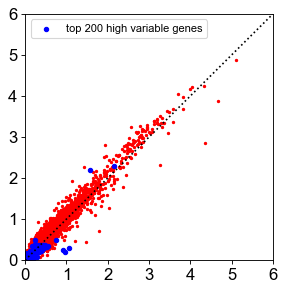

In [8]:
predict_data = sc.read_h5ad(f"../experiments/mice_exp6_infer_day_except_19_by_7_18_50_percent/interception_predict_to_day_19.h5ad")
print("predict_data:",predict_data)
predict_data.X = predict_data.X.astype(np.float64)
r2, pearsonr,real,predict = calc_r2_pearson(real_data,predict_data)
# keep only the same 200 HVGs
real_data_c = real_data[:, hvg_idx].copy()
predict_data_c = predict_data[:, hvg_idx].copy()

print("real_data:", real_data_c.shape)
print("predict_data:", predict_data_c.shape)

predict_data_c.X = predict_data_c.X.astype(np.float64)

r2, pearsonr, real_high, predict_high = calc_r2_pearson(  
    real_data_c,
    predict_data_c
)

print("R2:", r2)
print("Pearson:", pearsonr)
r2_list.append(r2)
pearsonr_list.append(pearsonr)
fig, ax = plt.subplots(1,1,figsize=(4,4),dpi=80)
plt.scatter(
    predict,
    real,
    s=4,
    c="red"
)
plt.scatter(
    predict_high,
    real_high,
    s=15,
    c="blue",
    label="top 200 high variable genes"
)
limit = np.ceil(max(np.max(predict), np.max(real)))
print(np.max(predict),np.max(real))
plt.plot([0, limit], [0, limit], color="black", linestyle=":")
plt.xlim([0, limit])
plt.ylim([0, limit])
ticks = np.arange(0, limit+1, 1)
ax.set_xticks(ticks)
ax.set_yticks(ticks)
ax.legend(loc="upper left", fontsize=10, frameon=True)
fig.savefig(os.path.join(f"day7_day10_predict_day19_big_training_set_50_percent_high_variable_genes.pdf"), bbox_inches="tight")

predict_data: AnnData object with n_obs × n_vars = 5592 × 55450
real_data: (5592, 200)
predict_data: (5592, 200)
R2: 0.8244338733456277
Pearson: 0.9155560684027465
4.728633035901662 4.8702583


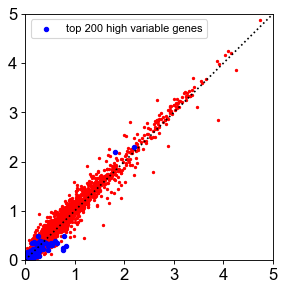

In [9]:
predict_data = sc.read_h5ad(f"../experiments/mice_exp6_infer_day_except_19_by_7_18_70_percent/interception_predict_to_day_19.h5ad")
print("predict_data:",predict_data)
predict_data.X = predict_data.X.astype(np.float64)
r2, pearsonr,real,predict = calc_r2_pearson(real_data,predict_data)
# keep only the same 200 HVGs
real_data_c = real_data[:, hvg_idx].copy()
predict_data_c = predict_data[:, hvg_idx].copy()

print("real_data:", real_data_c.shape)
print("predict_data:", predict_data_c.shape)

predict_data_c.X = predict_data_c.X.astype(np.float64)

r2, pearsonr, real_high, predict_high = calc_r2_pearson(  
    real_data_c,
    predict_data_c
)

print("R2:", r2)
print("Pearson:", pearsonr)
r2_list.append(r2)
pearsonr_list.append(pearsonr)
fig, ax = plt.subplots(1,1,figsize=(4,4),dpi=80)
plt.scatter(
    predict,
    real,
    s=4,
    c="red"
)
plt.scatter(
    predict_high,
    real_high,
    s=15,
    c="blue",
    label="top 200 high variable genes"
)
limit = np.ceil(max(np.max(predict), np.max(real)))
print(np.max(predict),np.max(real))
plt.plot([0, limit], [0, limit], color="black", linestyle=":")
plt.xlim([0, limit])
plt.ylim([0, limit])
ticks = np.arange(0, limit+1, 1)
ax.set_xticks(ticks)
ax.set_yticks(ticks)
ax.legend(loc="upper left", fontsize=10, frameon=True)
fig.savefig(os.path.join(f"day7_day10_predict_day19_big_training_set_70_percent_high_variable_genes.pdf"), bbox_inches="tight")

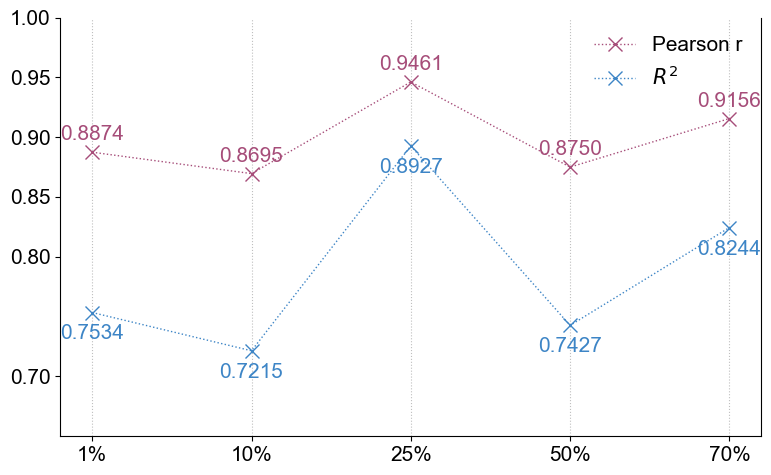

In [10]:
import numpy as np
import os
from matplotlib import font_manager
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.legend_handler import HandlerTuple
font_manager.fontManager.addfont("../../.././arial.ttf")
import numpy as np
import matplotlib.pyplot as plt
from brokenaxes import brokenaxes

plt.rcParams["font.family"] = "Arial"
plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 15,
    "pdf.fonttype": 42,
})
plt.rcParams["hatch.linewidth"] = 1

x = ["1%","10%","25%","50%","70%"]
# r2 =[0.9431,0.9493,0.9662,0.9594,0.9735]
# pearsonr = [0.9744,0.9867,0.9878,0.9850,0.9893]
fig,ax = plt.subplots(figsize=(8, 5))

ax.plot(
    x,
    pearsonr_list,
    marker="x", 
    # markerfacecolor="none",
    markersize=10,
    linestyle=":",
    linewidth=1,
    color="#A64D79",
    label="Pearson r"
)

ax.plot(
    x,
    r2_list,
    marker="x",
    # markerfacecolor="none",
    markersize=10,
    linestyle=":",
    linewidth=1,
    color="#3D85C6",
    label=r"$R^2$"
)

# Add numbers above Pearson r points
for i, value in enumerate(pearsonr_list):
    ax.text(
        i,
        value + 0.01,
        f"{value:.4f}",
        ha="center",
        fontsize=15,
        color="#A64D79"
    )

# Add numbers below R² points
for i, value in enumerate(r2_list):
    ax.text(
        i,
        value - 0.01,
        f"{value:.4f}",
        ha="center",
        va="top",
        fontsize=15,
        color="#3D85C6"
    )

# ax.set_yscale("function", functions=(
#     lambda y: np.where(y <= 0.8, y * 0.1, 0.08 + (y - 0.8)),
#     lambda y: np.where(y <= 0.08, y / 0.1, 0.8 + (y - 0.08))
# ))

ax.set_yticks([0.7,0.8, 0.85, 0.9, 0.95, 1.0])  # Upper section
ax.set_ylim([0.65,1])
ax.spines["top"].set_visible(False)
ax.legend(frameon=False)
ax.set_axisbelow(True)  # Keep grid lines behind the data
ax.grid(axis="x", linestyle=":", color="gray", linewidth=0.8, alpha=0.5)

plt.tight_layout()
fig.savefig(os.path.join(f"scaling_law_top_200_high_variable_genes.pdf"), bbox_inches="tight")

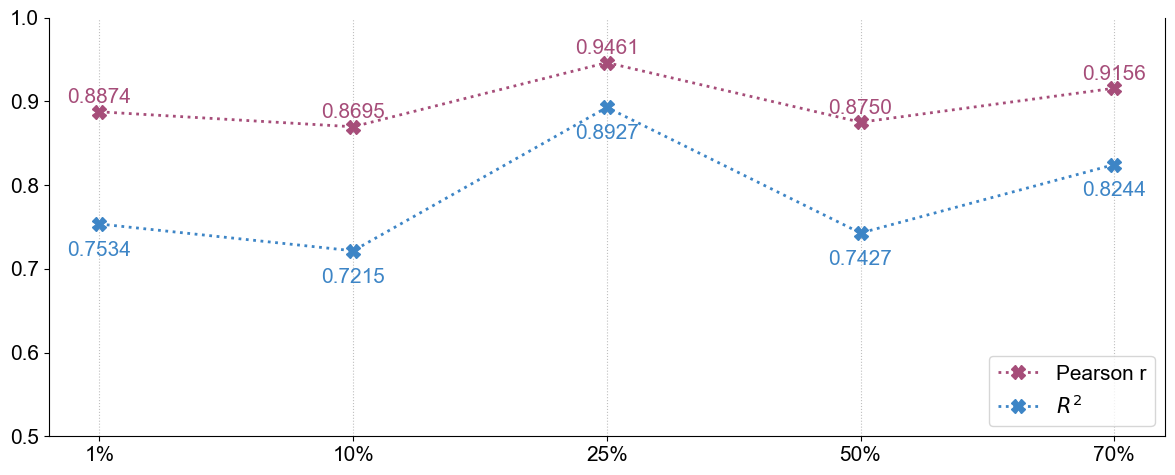

In [11]:
import numpy as np
import os
from matplotlib import font_manager
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.legend_handler import HandlerTuple
font_manager.fontManager.addfont("../../.././arial.ttf")
import numpy as np
import matplotlib.pyplot as plt
from brokenaxes import brokenaxes

plt.rcParams["font.family"] = "Arial"
plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 15,
    "pdf.fonttype": 42,
})
plt.rcParams["hatch.linewidth"] = 1

# --------------------------------------------------
# Example benchmark data
# Replace these values with your own results
# --------------------------------------------------

x = ["1%","10%","25%","50%","70%"]
# r2_list
# pearsonr_list
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    x,
    pearsonr_list,
    marker="X",
    markersize=10,
    linestyle=":",
    linewidth=2,
    color="#A64D79",
    label="Pearson r"
)

ax.plot(
    x,
    r2_list,
    marker="X",
    markersize=10,
    linestyle=":",
    linewidth=2,
    color="#3D85C6",
    label=r"$R^2$"
)

# Add numbers above Pearson r points
for i, value in enumerate(pearsonr_list):
    ax.text(
        i,
        value + 0.01,
        f"{value:.4f}",
        ha="center",
        fontsize=15,
        color="#A64D79"
    )

# Add numbers below R² points
for i, value in enumerate(r2_list):
    ax.text(
        i,
        value - 0.02,
        f"{value:.4f}",
        ha="center",
        va="top",
        fontsize=15,
        color="#3D85C6"
    )

ax.set_ylim(0.5, 1.0)
ax.spines["top"].set_visible(False)
ax.legend(loc="lower right", fontsize=15, frameon=True)
ax.grid(axis="x", linestyle=":", color="gray", linewidth=0.8, alpha=0.5)

plt.tight_layout()
fig.savefig(os.path.join(f"scaling_law_top_200_high_variable_genes.pdf"), bbox_inches="tight")